In [23]:
import pandas as pd;
import numpy as np;
import os
import sqlite3

In [24]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

DB_PATH = Path("../data/raw/customers.db")

conn = sqlite3.connect(DB_PATH)

In [26]:
df_raw = pd.read_sql_query(
    "SELECT * FROM customers",
    conn
)

df = df_raw.copy()

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [27]:
print(df.shape)
df.info()

df.head()

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [29]:
print("Duplicate rows : ",df.duplicated().sum())
print(df.isnull().sum().sum(),"missing values")
df["Churn"].value_counts(normalize=True)*100

Duplicate rows :  0
0 missing values


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [30]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors='coerce')
print("Missing TotalCharges:", df['TotalCharges'].isnull().sum())


df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'Churn']]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,Churn
488,4472-LVYGI,0,52.55,No
753,3115-CZMZD,0,20.25,No
936,5709-LVOEQ,0,80.85,No
1082,4367-NUYAO,0,25.75,No
1340,1371-DWPAZ,0,56.05,No
3331,7644-OMVMY,0,19.85,No
3826,3213-VVOLG,0,25.35,No
4380,2520-SGTTA,0,20.00,No
5218,2923-ARZLG,0,19.70,No
6670,4075-WKNIU,0,73.35,No


In [31]:
df["SeniorCitizen"]= df["SeniorCitizen"].map({0:'No',1:'Yes'})
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors='coerce').fillna(0)
df["MultipleLines"]=df["MultipleLines"].replace("No phone service","No")
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection','TechSupport', 'StreamingTV', 'StreamingMovies']
for cols in internet_cols :
    df[cols] = df[cols].replace("No phone service","No")
# customer_ids = df['customerID'].copy()

df = df.drop(columns='customerID', errors='ignore')

df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(df.shape)
print(df.isnull().sum().sum(), "missing values")
print(df['Churn'].mean())

(7043, 20)
0 missing values
0.2653698707936959


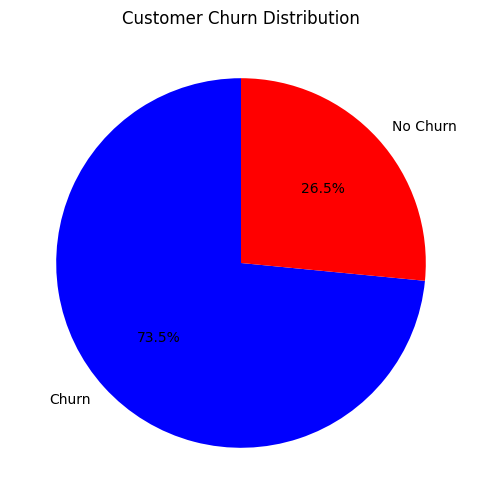

In [32]:
fig ,ax = plt.subplots(figsize=(6,6))
counts = df["Churn"].value_counts().sort_index()
ax.pie(counts,labels=["Churn","No Churn"],autopct="%1.1f%%",colors=['blue','red'],startangle=90)
ax.set_title("Customer Churn Distribution")
plt.show()

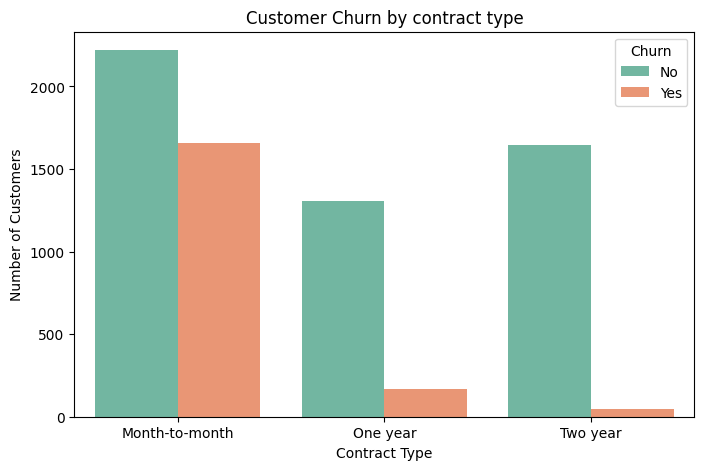

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(
    data= df,
    x='Contract',
    hue='Churn',
    palette='Set2'
)

plt.title('Customer Churn by contract type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No', 'Yes'])
plt.show()

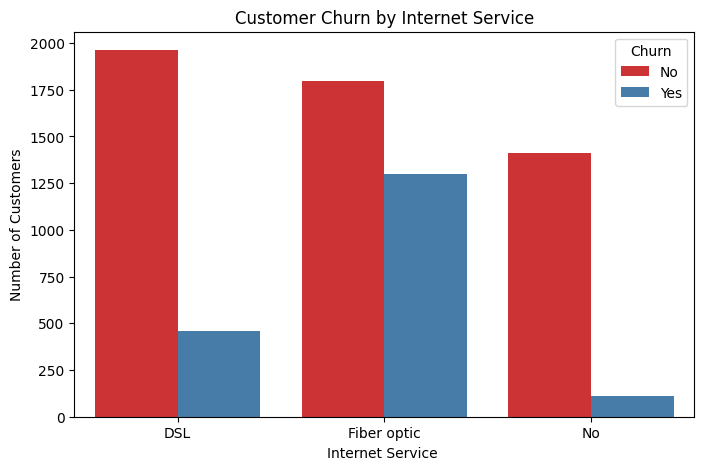

In [34]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='InternetService',
    hue = 'Churn',
    palette="Set1"
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service ')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

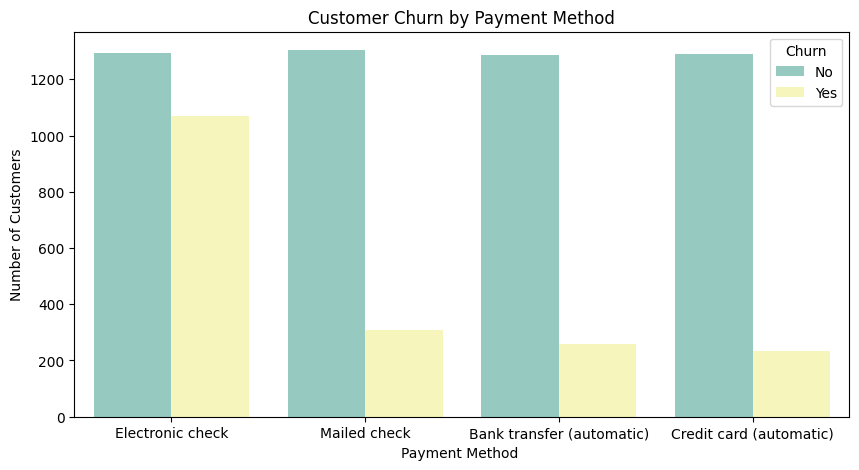

In [35]:
plt.figure(figsize=(10,5))
sns.countplot(
    data=df,
    x='PaymentMethod',
    hue = 'Churn',
    palette="Set3"
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method ')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

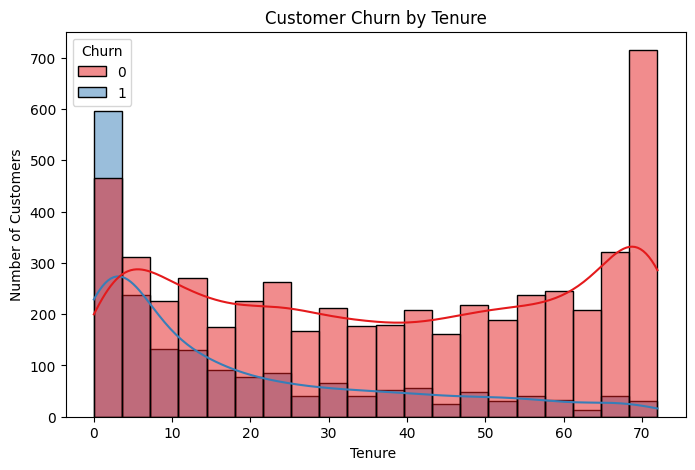

In [36]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='tenure',
    kde=True,
    bins=20,
    hue = 'Churn',
    palette="Set1"
)

plt.title('Customer Churn by Tenure')
plt.xlabel('Tenure ')
plt.ylabel('Number of Customers')
plt.show()

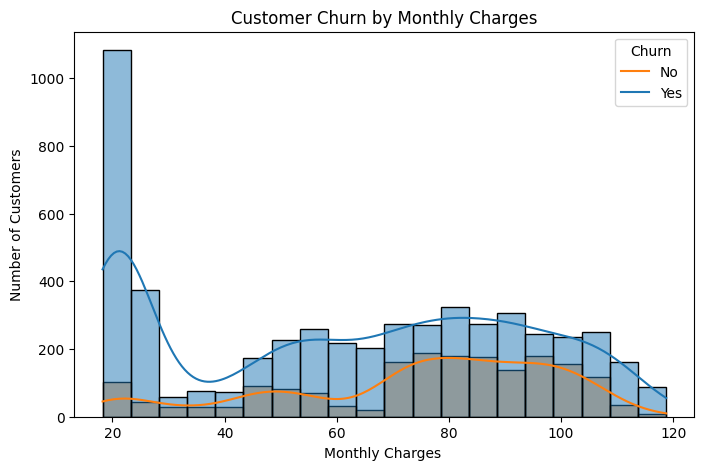

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='MonthlyCharges',
    kde=True,
    bins=20,
    hue = 'Churn',
    color="blue"
)

plt.title('Customer Churn by Monthly Charges')
plt.xlabel('Monthly Charges ')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

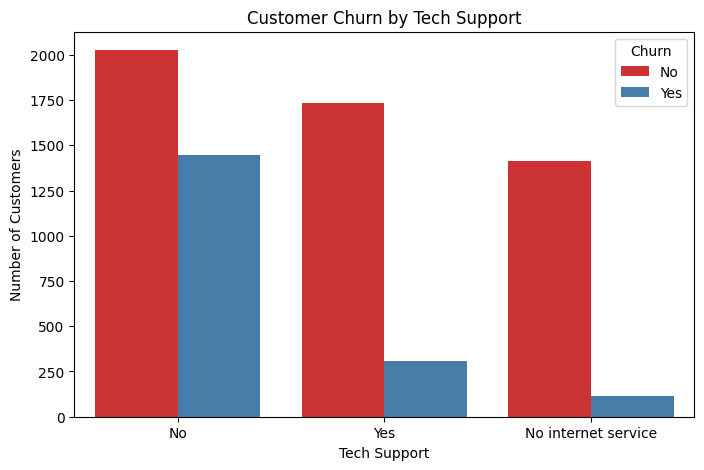

In [38]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='TechSupport',
    hue='Churn',
    palette='Set1'
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

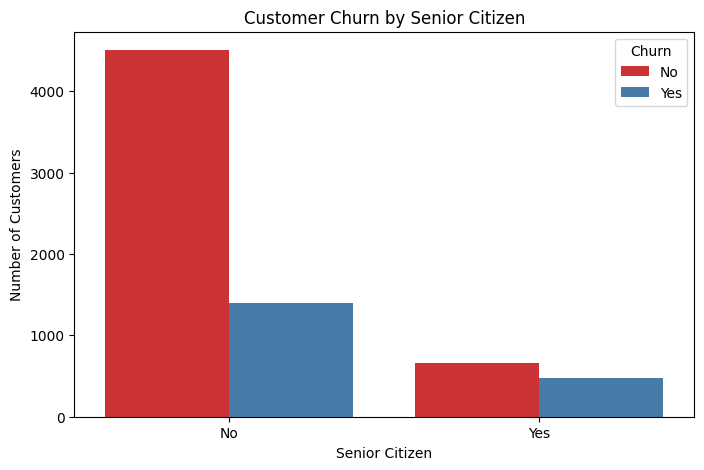

In [39]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='SeniorCitizen',
    hue='Churn',
    palette='Set1'
)

plt.title('Customer Churn by Senior Citizen')
plt.xlabel('Senior Citizen')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

C:\Users\abhis\AppData\Local\Temp\ipykernel_16036\866489321.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:blue'` for the same effect.

  sns.countplot(


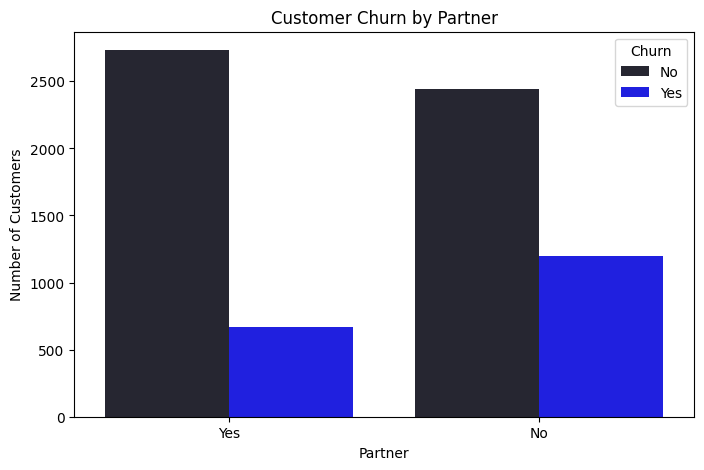

In [40]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='Partner',
    hue='Churn',
    color='blue'
)

plt.title('Customer Churn by Partner')
plt.xlabel('Partner')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

C:\Users\abhis\AppData\Local\Temp\ipykernel_16036\681969965.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:blue'` for the same effect.

  sns.countplot(


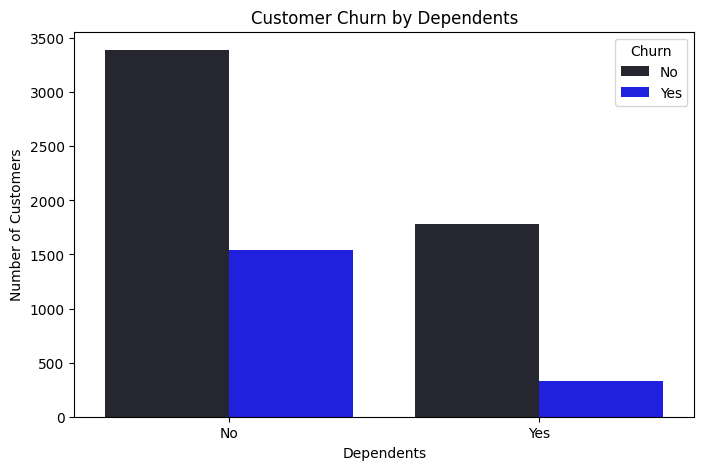

In [41]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='Dependents',
    hue='Churn',
    color='blue'
)

plt.title('Customer Churn by Dependents')
plt.xlabel('Dependents')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

C:\Users\abhis\AppData\Local\Temp\ipykernel_16036\921366926.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:blue'` for the same effect.

  sns.countplot(


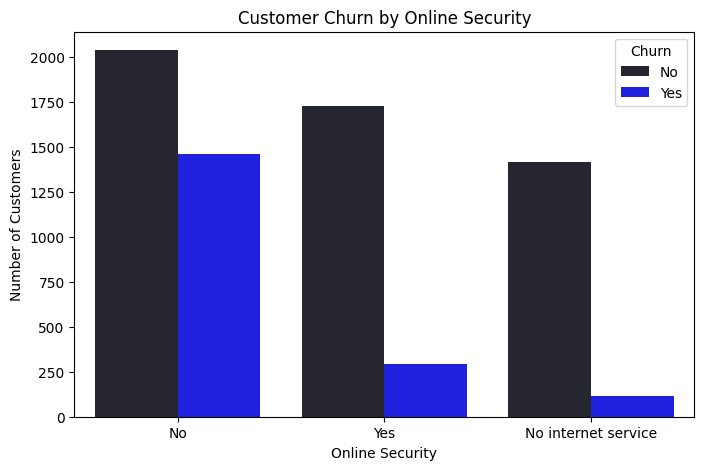

In [42]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='OnlineSecurity',
    hue='Churn',
    color='blue'
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')
plt.legend(title='Churn',labels=['No','Yes'])
plt.show()

In [43]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,No,Yes,Yes,11,No,No,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [44]:
from pathlib import Path

processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    processed_dir / "cleaned_churn.csv",
    index=False
)